In [33]:
import itertools, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2, SamplerV2

backend   = AerSimulator()
pm        = generate_preset_pass_manager(optimization_level=2, backend=backend)
estimator = EstimatorV2()
sampler   = SamplerV2()

## Modelo

In [34]:
# ---------------- Problema direto ----------------

def build_M(h, offsets):
    # Matriz de tempos de transito, triangular inferior.
    # Raio i reflete na base da camada i. Angulo fixo por raio (raio reto):
    # tan(theta_i) = (offset_i/2) / H_i, com H_i = profundidade acumulada ate a base da camada i.
    m = len(h)
    H = np.cumsum(h)
    M = np.zeros((m, m))
    for i in range(m):
        theta = np.arctan((offsets[i] / 2.0) / H[i])
        for j in range(i + 1):
            M[i, j] = 2.0 * h[j] / np.cos(theta)
    return M

In [35]:
# ---------------- Modelo sintetico ----------------
M_LAYERS = 3          # numero de camadas
R_BITS   = 3          # bits por variavel real (R=3, como nos artigos)
N_QUBITS = M_LAYERS * R_BITS

h_true      = np.array([400.0, 350.0, 450.0])       # espessuras (m)
offsets     = np.array([600.0, 900.0, 1200.0])      # afastamentos fonte-receptor (m)
v_true      = np.array([1800.0, 2400.0, 3000.0])    # velocidades verdadeiras (m/s)
s_true      = 1.0 / v_true

M    = build_M(h_true, offsets)
t_obs = M @ s_true

print(f"Camadas: {M_LAYERS} | R = {R_BITS} bits | qubits = R x M = {N_QUBITS}")
print(f"(Albino et al. 2022 usaram 9, 12 e 18 qubits para 3, 4 e 6 camadas)\n")
print("Matriz M (m), triangular inferior:")
print(np.round(M, 1))
print(f"\nNumero de condicao de M: {np.linalg.cond(M):.2f}  (problema bem condicionado)")
print("\nTempos de transito observados (s):")
for i, tt in enumerate(t_obs):
    print(f"  t_{i+1} (reflexao na base da camada {i+1}): {tt:.6f}")

Camadas: 3 | R = 3 bits | qubits = R x M = 9
(Albino et al. 2022 usaram 9, 12 e 18 qubits para 3, 4 e 6 camadas)

Matriz M (m), triangular inferior:
[[1000.     0.     0. ]
 [ 933.   816.3    0. ]
 [ 894.4  782.6 1006.2]]

Numero de condicao de M: 3.99  (problema bem condicionado)

Tempos de transito observados (s):
  t_1 (reflexao na base da camada 1): 0.555556
  t_2 (reflexao na base da camada 2): 0.858446
  t_3 (reflexao na base da camada 3): 1.158407


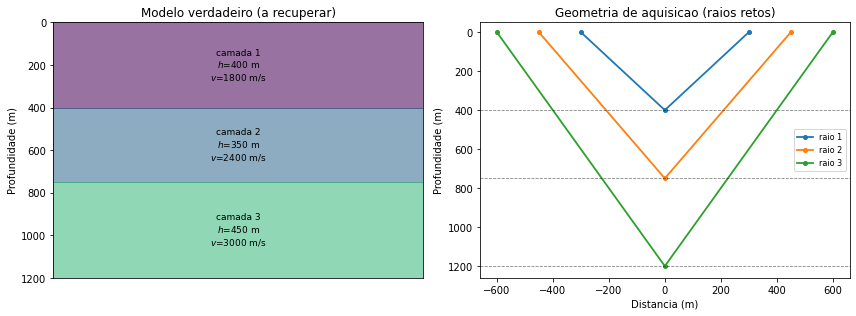

In [36]:
# ---------------- Visualizacao do modelo ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
z = np.concatenate([[0], np.cumsum(h_true)])
for j in range(M_LAYERS):
    ax.axhspan(z[j], z[j+1], color=plt.cm.viridis(j / M_LAYERS), alpha=.55)
    ax.text(0.5, (z[j] + z[j+1]) / 2,
            f"camada {j+1}\n$h$={h_true[j]:.0f} m\n$v$={v_true[j]:.0f} m/s",
            ha="center", va="center", fontsize=9)
ax.set_ylim(z[-1], 0); ax.set_xlim(0, 1); ax.set_xticks([])
ax.set_ylabel("Profundidade (m)"); ax.set_title("Modelo verdadeiro (a recuperar)")

ax = axes[1]
for i in range(M_LAYERS):
    Hi = np.cumsum(h_true)[i]
    xs = [-offsets[i]/2, 0, offsets[i]/2]
    ys = [0, Hi, 0]
    ax.plot(xs, ys, "-o", lw=1.8, ms=4, label=f"raio {i+1}")
for zz in z[1:]:
    ax.axhline(zz, color="k", lw=.8, ls="--", alpha=.5)
ax.set_ylim(z[-1] * 1.05, -50); ax.set_xlabel("Distancia (m)"); ax.set_ylabel("Profundidade (m)")
ax.set_title("Geometria de aquisicao (raios retos)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## QUBO

In [37]:
def expand_binary(M, R):
    # A[k, i*R+r] = M[k,i] * 2^(-r)  =>  A q = M x
    m, n = M.shape
    A = np.zeros((m, n * R))
    for i in range(n):
        for r in range(R):
            A[:, i * R + r] = M[:, i] * (2.0 ** (-r))
    return A


def qubo_from_ls(A, b):
    # QUBO de min ||A q - b||^2. Souza et al. eqs. (14)-(15).
    n = A.shape[1]
    Q = np.zeros((n, n))
    for i in range(n):
        Q[i, i] = np.sum(A[:, i] * (A[:, i] - 2.0 * b))
    for i in range(n):
        for j in range(i + 1, n):
            Q[i, j] = 2.0 * np.sum(A[:, i] * A[:, j])
    return Q, float(b @ b)


def q_to_x(q, n_real, R):
    # decodifica vetor binario em vetor real
    q = np.asarray(q, float).reshape(n_real, R)
    return q @ (2.0 ** (-np.arange(R)))


def qubo_energy(Q, off, q):
    q = np.asarray(q, float)
    return float(q @ Q @ q + off)


def brute_force(Q, off):
    # referencia exata (viavel apenas para n pequeno)
    n = Q.shape[0]
    best, bc = None, np.inf
    for bits in itertools.product([0, 1], repeat=n):
        c = qubo_energy(Q, off, bits)
        if c < bc:
            bc, best = c, list(bits)
    return best, bc

In [38]:
# ---------------- Construcao da primeira iteracao ----------------
s0_init = np.full(M_LAYERS, 1.0 / 2400.0)   # palpite: meio homogeneo a 2400 m/s
L_init  = 3.0e-4                            # limite de busca em lentidao

b = (t_obs + L_init * (M @ np.ones(M_LAYERS)) - M @ s0_init) / L_init
A = expand_binary(M, R_BITS)
Q, offset = qubo_from_ls(A, b)

print(f"A: {A.shape}   Q: {Q.shape}  ->  {Q.shape[0]} qubits")
dens = np.count_nonzero(np.triu(Q, 1)) / (Q.shape[0] * (Q.shape[0] - 1) / 2)
print(f"Densidade do grafo QUBO (fora da diagonal): {dens:.1%}")
print(f"\nQ (primeiras 5x5 entradas):\n{np.round(Q[:5,:5], 1)}")

A: (3, 9)   Q: (9, 9)  ->  9 qubits
Densidade do grafo QUBO (fora da diagonal): 100.0%

Q (primeiras 5x5 entradas):
[[-9366192.6  2670400.   1335200.   2923200.   1461600. ]
 [       0.  -5350696.3   667600.   1461600.    730800. ]
 [       0.         0.  -2842248.1   730800.    365400. ]
 [       0.         0.         0.  -6692933.3  1278900. ]
 [       0.         0.         0.         0.  -3666191.7]]


In [39]:
q_bf, e_bf = brute_force(Q, offset)
x_bf = q_to_x(q_bf, M_LAYERS, R_BITS)
s_bf = s0_init + L_init * (x_bf - 1.0)

print(f"q* (forca bruta) = {q_bf}")
print(f"x*               = {x_bf}")
print(f"\nApos 1 iteracao:")
print(f"  v recuperado = {np.round(1.0 / s_bf, 1)} m/s")
print(f"  v verdadeiro = {v_true} m/s")
err1 = np.abs(1.0 / s_bf - v_true) / v_true * 100
print(f"  erro relativo = {np.round(err1, 2)} %  (max {err1.max():.2f}%)")

q* (forca bruta) = [1, 1, 0, 1, 0, 0, 0, 1, 1]
x*               = [1.5  1.   0.75]

Apos 1 iteracao:
  v recuperado = [1764.7 2400.  2926.8] m/s
  v verdadeiro = [1800. 2400. 3000.] m/s
  erro relativo = [1.96 0.   2.44] %  (max 2.44%)


In [40]:
def qubo_to_ising(Q, off):
    # q_j = (1 - z_j)/2
    n = Q.shape[0]
    Qs = (Q + Q.T) / 2.0
    d  = np.diag(Qs).copy()
    O  = Qs - np.diag(d)
    h  = -d / 2.0
    J  = np.zeros((n, n))
    c  = off + d.sum() / 2.0
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            qq = O[i, j]
            c    += qq / 4.0
            h[i] -= qq / 4.0
            h[j] -= qq / 4.0
            J[i, j] += qq / 4.0
    return h, J, c


def ising_energy(h, J, c, z):
    z = np.asarray(z, float)
    return float(h @ z + z @ J @ z + c)


def ising_to_pauli(h, J, n, tol=1e-10):
    terms = []
    for i in range(n):
        if abs(h[i]) > tol:
            p = ["I"] * n; p[n - 1 - i] = "Z"
            terms.append(("".join(p), float(h[i])))
    for i in range(n):
        for j in range(i + 1, n):
            c = J[i, j] + J[j, i]
            if abs(c) > tol:
                p = ["I"] * n; p[n - 1 - i] = "Z"; p[n - 1 - j] = "Z"
                terms.append(("".join(p), float(c)))
    return SparsePauliOp.from_list(terms)

In [41]:
# ---------------- Verificacao numerica da equivalencia ----------------
alpha = np.abs(Q).max()                       # normalizacao
h_is, J_is, c_is = qubo_to_ising(Q / alpha, offset / alpha)
H_cost = ising_to_pauli(h_is, J_is, N_QUBITS)

err = 0.0
for bits in itertools.product([0, 1], repeat=N_QUBITS):
    z = [1 - 2 * bb for bb in bits]
    err = max(err, abs(qubo_energy(Q / alpha, offset / alpha, bits)
                       - ising_energy(h_is, J_is, c_is, z)))

print(f"Fator de normalizacao alpha = {alpha:.3e}")
print(f"Hamiltoniano: {len(H_cost)} termos de Pauli")
print(f"Erro maximo QUBO vs Ising sobre os {2**N_QUBITS} estados: {err:.2e}")
print("Transformacao exata." if err < 1e-8 else "ERRO na transformacao.")

Fator de normalizacao alpha = 9.366e+06
Hamiltoniano: 45 termos de Pauli
Erro maximo QUBO vs Ising sobre os 512 estados: 5.00e-16
Transformacao exata.


## QAOA

In [42]:
def qaoa_solve(Q, off, reps=3, restarts=3, shots=4096, seed=0, maxiter=250,
               return_details=False):
    n = Q.shape[0]
    a = np.abs(Q).max()
    hh, JJ, cc = qubo_to_ising(Q / a, off / a)
    H = ising_to_pauli(hh, JJ, n)

    raw  = QAOAAnsatz(cost_operator=H, reps=reps)
    rawm = raw.copy(); rawm.measure_all()
    ans, ansm = pm.run(raw), pm.run(rawm)
    HL = H.apply_layout(ans.layout)           # remapeia o Hamiltoniano apos transpilacao

    rng = np.random.default_rng(seed)
    hist = []
    def energia(theta):
        val = float(estimator.run([(ans, HL, theta)]).result()[0].data.evs)
        hist.append(val)
        return val

    best = None
    for _ in range(restarts):
        r = minimize(energia, rng.uniform(0, np.pi, ans.num_parameters),
                     method="COBYLA", options={"maxiter": maxiter})
        if best is None or r.fun < best.fun:
            best = r

    counts = sampler.run([(ansm, best.x)], shots=shots).result()[0].data.meas.get_counts()

    # melhor entre os shots
    bq, be = None, np.inf
    for sbits, ct in counts.items():
        q = [int(z) for z in sbits[::-1]]      # little-endian -> ordem das variaveis
        e = qubo_energy(Q, off, q)
        if e < be:
            be, bq = e, q

    if return_details:
        modo = max(counts.items(), key=lambda kv: kv[1])
        return bq, be, counts, [int(z) for z in modo[0][::-1]], hist, ans
    return bq, be

In [43]:
# ---------------- Circuito ----------------
_raw = QAOAAnsatz(cost_operator=H_cost, reps=3)
_tr  = pm.run(_raw)
print(f"Qubits: {_raw.num_qubits} | p = 3 -> {_raw.num_parameters} parametros")
print(f"Profundidade transpilada: {_tr.depth()}")
print(f"Portas: {dict(_tr.count_ops())}")

Qubits: 9 | p = 3 -> 6 parametros
Profundidade transpilada: 40
Portas: {'rzz': 108, 'rz': 27, 'rx': 27, 'h': 9}


In [44]:
# ---------------- QAOA na primeira iteracao----------------
t0 = time.time()
q_q, e_q, counts, q_modo, hist, ans = qaoa_solve(Q, offset, reps=3, restarts=3,
                                                 seed=1, return_details=True)
print(f"Tempo: {time.time() - t0:.1f} s\n")
print(f"Forca bruta        q = {q_bf}   E = {e_bf:.4e}")
print(f"QAOA melhor-de-shots q = {q_q}   E = {e_q:.4e}")
print(f"QAOA modo (mais frequente) q = {q_modo}   E = {qubo_energy(Q, offset, q_modo):.4e}")
print("\n=> " + ("QAOA encontrou o otimo global." if q_q == q_bf else "QAOA NAO encontrou o otimo."))

Tempo: 25.3 s

Forca bruta        q = [1, 1, 0, 1, 0, 0, 0, 1, 1]   E = 6.2962e+03
QAOA melhor-de-shots q = [1, 1, 0, 1, 0, 0, 0, 1, 1]   E = 6.2962e+03
QAOA modo (mais frequente) q = [1, 1, 0, 1, 1, 0, 0, 1, 0]   E = 2.3771e+05

=> QAOA encontrou o otimo global.


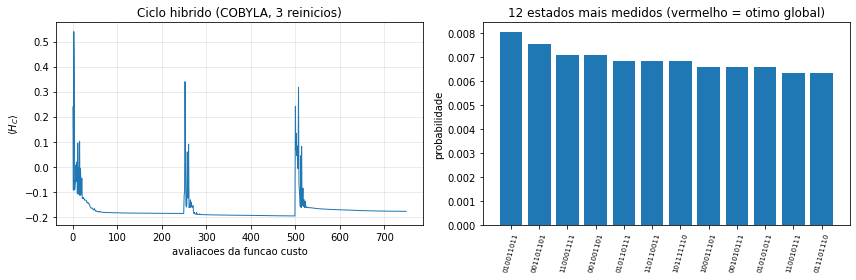

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist, lw=1)
axes[0].set_xlabel("avaliacoes da funcao custo"); axes[0].set_ylabel(r"$\langle H_C\rangle$")
axes[0].set_title("Ciclo hibrido (COBYLA, 3 reinicios)"); axes[0].grid(alpha=.3)

top = sorted(counts.items(), key=lambda kv: -kv[1])[:12]
alvo = "".join(str(b) for b in q_bf[::-1])
cores = ["tab:red" if s == alvo else "tab:blue" for s, _ in top]
axes[1].bar(range(len(top)), [c / 4096 for _, c in top], color=cores)
axes[1].set_xticks(range(len(top)))
axes[1].set_xticklabels([s for s, _ in top], rotation=75, fontsize=7)
axes[1].set_ylabel("probabilidade")
axes[1].set_title("12 estados mais medidos (vermelho = otimo global)")
plt.tight_layout(); plt.show()

In [31]:
N_ITER = 8
s_cur, L_cur = s0_init.copy(), L_init
hist_v, hist_err, match = [1.0 / s_cur], [], []

t0 = time.time()
for it in range(1, N_ITER + 1):
    b_k = (t_obs + L_cur * (M @ np.ones(M_LAYERS)) - M @ s_cur) / L_cur
    Q_k, off_k = qubo_from_ls(A, b_k)

    q_ref, _ = brute_force(Q_k, off_k)                      # auditoria
    q_k, _   = qaoa_solve(Q_k, off_k, reps=3, restarts=3, seed=10 * it)

    s_cur = s_cur + L_cur * (q_to_x(q_k, M_LAYERS, R_BITS) - 1.0)
    L_cur *= 0.25

    e = np.abs(1.0 / s_cur - v_true) / v_true * 100
    hist_v.append(1.0 / s_cur); hist_err.append(e.max()); match.append(q_k == q_ref)
    print(f"it {it}: v = {np.round(1.0/s_cur, 1)} m/s | erro max = {e.max():7.4f}% | "
          f"QAOA {'==' if q_k == q_ref else '!='} forca bruta")

print(f"\nTempo total: {time.time() - t0:.1f} s")
print(f"QAOA igualou a forca bruta em {sum(match)}/{N_ITER} iteracoes.")
print(f"\nVelocidade final     : {np.round(1.0/s_cur, 2)} m/s")
print(f"Velocidade verdadeira: {v_true} m/s")
print(f"Erro relativo final  : {hist_err[-1]:.4f} %")

it 1: v = [1764.7 2400.  2926.8] m/s | erro max =  2.4390% | QAOA == forca bruta
it 2: v = [1825.1 2400.  2926.8] m/s | erro max =  2.4390% | QAOA == forca bruta
it 3: v = [1794.4 2400.  3009.4] m/s | erro max =  0.3135% | QAOA == forca bruta
it 4: v = [1798.2 2406.8 2998.8] m/s | erro max =  0.2820% | QAOA == forca bruta
it 5: v = [1800.1 2401.7 2998.8] m/s | erro max =  0.0704% | QAOA == forca bruta
it 6: v = [1799.8 2400.4 3000.1] m/s | erro max =  0.0176% | QAOA == forca bruta
it 7: v = [1800.  2400.1 3000. ] m/s | erro max =  0.0044% | QAOA == forca bruta
it 8: v = [1800. 2400. 3000.] m/s | erro max =  0.0011% | QAOA == forca bruta

Tempo total: 211.7 s
QAOA igualou a forca bruta em 8/8 iteracoes.

Velocidade final     : [1800.   2400.03 2999.98] m/s
Velocidade verdadeira: [1800. 2400. 3000.] m/s
Erro relativo final  : 0.0011 %


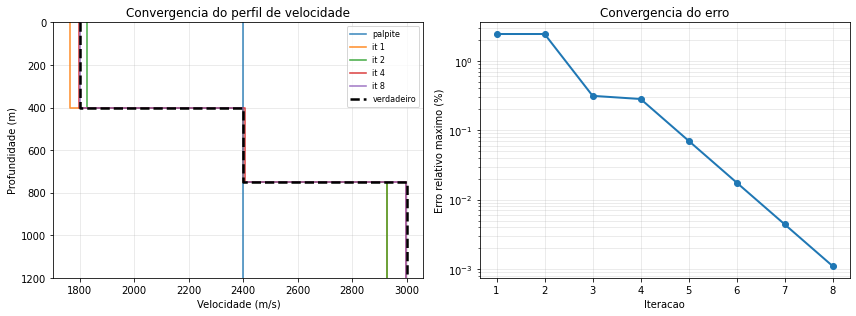

In [32]:
hist_v = np.array(hist_v)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 
ax = axes[0]
zc = np.concatenate([[0], np.cumsum(h_true)])
def stairs(v):
    xs, ys = [], []
    for j in range(len(v)):
        xs += [v[j], v[j]]; ys += [zc[j], zc[j+1]]
    return xs, ys
for k in [0, 1, 2, 4, len(hist_v) - 1]:
    xs, ys = stairs(hist_v[k])
    ax.plot(xs, ys, lw=1.6, alpha=.85, label=f"it {k}" if k else "palpite")
xs, ys = stairs(v_true)
ax.plot(xs, ys, "k--", lw=2.5, label="verdadeiro")
ax.set_ylim(zc[-1], 0); ax.set_xlabel("Velocidade (m/s)"); ax.set_ylabel("Profundidade (m)")
ax.set_title("Convergencia do perfil de velocidade"); ax.legend(fontsize=8); ax.grid(alpha=.3)

# erro vs iteracao 
ax = axes[1]
ax.semilogy(range(1, N_ITER + 1), hist_err, "o-", lw=2)
ax.set_xlabel("Iteracao"); ax.set_ylabel("Erro relativo maximo (%)")
ax.set_title("Convergencia do erro"); ax.grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()